In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =========================================================
# 1. load data
# =========================================================
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

dates = pd.to_datetime(df_fit["date"]).reset_index(drop=True)
obs_cases = df_fit["cases_7d"].values.astype(float)
T = len(obs_cases)

# =========================================================
# 2. fixed settings
# =========================================================
N = 67_000_000
gamma_fixed = 1 / 7
tau_fixed = 4
eps = 1.0

# choose final model here
MODEL_NAME = "mm_burden"   # change to "rational_burden" if you want

# =========================================================
# 3. breakpoints
# =========================================================
break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]

for d in break_dates:
    if pd.Timestamp(d) not in set(df_fit["date"]):
        raise ValueError(f"Breakpoint {d} not found in df_fit.")

break_indices = [
    int(np.where(df_fit["date"] == pd.Timestamp(d))[0][0])
    for d in break_dates
]

def get_segment_bounds(T, break_indices):
    bounds = [0] + break_indices + [T]
    return [(bounds[i], bounds[i + 1]) for i in range(len(bounds) - 1)]

segment_bounds = get_segment_bounds(T, break_indices)
n_seg = len(segment_bounds)

print("Break dates:", break_dates)
print("Break indices:", break_indices)
print("Segment bounds:", segment_bounds)

# =========================================================
# 4. helpers
# =========================================================
def apply_fixed_delay(x, tau):
    tau = int(tau)
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y

def get_segment_index(t_idx, segment_bounds):
    for j, (a, b) in enumerate(segment_bounds):
        if a <= t_idx < b:
            return j
    return len(segment_bounds) - 1

# =========================================================
# 5. burden: cumulative delayed observed cases within each segment
# =========================================================
obs_proxy = apply_fixed_delay(obs_cases, tau_fixed)

burden = np.zeros(T)
for j, (a, b) in enumerate(segment_bounds):
    seg_series = obs_proxy[a:b].copy()
    seg_cum = np.cumsum(seg_series)
    denom = np.max(seg_cum)
    if denom <= 0:
        denom = 1.0
    burden[a:b] = seg_cum / denom   # normalized to [0, 1]

# =========================================================
# 6. burden-driven beta models
# =========================================================
def beta_t_value(model_name, t_idx, param_list, burden, segment_bounds):
    seg_idx = get_segment_index(t_idx, segment_bounds)
    z = burden[t_idx]
    p = param_list[seg_idx]

    if model_name == "constant":
        beta_t = p["beta0"]

    elif model_name == "exp_burden":
        beta_t = p["beta0"] * np.exp(-p["k"] * z)

    elif model_name == "rational_burden":
        beta_t = p["beta0"] / (1.0 + p["k"] * z)

    elif model_name == "linear_burden":
        beta_t = max(p["beta_min"], p["beta0"] - p["k"] * z)

    elif model_name == "mm_burden":
        beta_t = p["beta0"] / (1.0 + p["k"] * (z / (p["h"] + z + 1e-12)))

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return max(1e-8, beta_t)

# =========================================================
# 7. parameter unpacking
# =========================================================
def unpack_theta(model_name, theta, n_seg):
    params = []
    pos = 0

    if model_name == "constant":
        for _ in range(n_seg):
            params.append({"beta0": theta[pos]})
            pos += 1

    elif model_name in ["exp_burden", "rational_burden"]:
        for _ in range(n_seg):
            params.append({
                "beta0": theta[pos],
                "k": theta[pos + 1]
            })
            pos += 2

    elif model_name == "linear_burden":
        for _ in range(n_seg):
            params.append({
                "beta0": theta[pos],
                "k": theta[pos + 1],
                "beta_min": theta[pos + 2]
            })
            pos += 3

    elif model_name == "mm_burden":
        for _ in range(n_seg):
            params.append({
                "beta0": theta[pos],
                "k": theta[pos + 1],
                "h": theta[pos + 2]
            })
            pos += 3

    else:
        raise ValueError(f"Unknown model: {model_name}")

    rho = theta[pos]
    I0 = theta[pos + 1]

    return params, rho, I0

def make_x0_bounds(model_name, n_seg, first_case):
    x0 = []
    bounds = []

    if model_name == "constant":
        for _ in range(n_seg):
            x0 += [0.20]
            bounds += [(1e-6, 1.0)]

    elif model_name in ["exp_burden", "rational_burden"]:
        for _ in range(n_seg):
            x0 += [0.22, 2.0]
            bounds += [(1e-6, 1.0), (0.0, 20.0)]

    elif model_name == "linear_burden":
        for _ in range(n_seg):
            x0 += [0.22, 0.15, 0.03]
            bounds += [(1e-6, 1.0), (0.0, 1.0), (1e-6, 0.5)]

    elif model_name == "mm_burden":
        for _ in range(n_seg):
            x0 += [0.22, 2.0, 0.3]
            bounds += [(1e-6, 1.0), (0.0, 30.0), (0.01, 2.0)]

    else:
        raise ValueError(f"Unknown model: {model_name}")

    x0 += [1.0, first_case * 5.0]   # rho, I0
    bounds += [(1e-6, 100.0), (1.0, 5_000_000.0)]

    return np.array(x0, dtype=float), bounds

# =========================================================
# 8. discrete-time SIR
# =========================================================
def simulate_discrete_sir(model_name, theta, burden, gamma, N, T, tau, segment_bounds, n_seg):
    params, rho, I0 = unpack_theta(model_name, theta, n_seg)

    if rho <= 0 or I0 <= 0 or I0 >= N:
        raise ValueError("Invalid rho or I0")

    S = np.zeros(T)
    I = np.zeros(T)
    R = np.zeros(T)
    beta_path = np.zeros(T)
    incidence = np.zeros(T)

    S[0] = N - I0
    I[0] = I0
    R[0] = 0.0

    for t in range(T):
        beta_path[t] = beta_t_value(model_name, t, params, burden, segment_bounds)
        incidence[t] = beta_path[t] * S[t] * I[t] / N

        if t < T - 1:
            new_inf = incidence[t]
            new_rec = gamma * I[t]

            S[t + 1] = max(0.0, S[t] - new_inf)
            I[t + 1] = max(0.0, I[t] + new_inf - new_rec)
            R[t + 1] = max(0.0, R[t] + new_rec)

    fitted_cases = rho * apply_fixed_delay(incidence, tau)

    return {
        "S": S,
        "I": I,
        "R": R,
        "beta_path": beta_path,
        "incidence": incidence,
        "fitted_cases": fitted_cases,
        "rho": rho,
        "I0": I0,
        "params": params,
    }

# =========================================================
# 9. regularization + loss
# =========================================================
def regularization_penalty(theta, lam=1e-4):
    return lam * np.sum(theta[:-2] ** 2)

def loss_fn(theta, model_name):
    try:
        sim = simulate_discrete_sir(
            model_name=model_name,
            theta=theta,
            burden=burden,
            gamma=gamma_fixed,
            N=N,
            T=T,
            tau=tau_fixed,
            segment_bounds=segment_bounds,
            n_seg=n_seg
        )

        fitted = sim["fitted_cases"]

        if np.any(np.isnan(fitted)) or np.any(np.isinf(fitted)):
            return 1e20
        if np.any(fitted < 0):
            return 1e20

        fit_loss = np.mean((np.log(fitted + eps) - np.log(obs_cases + eps)) ** 2)
        reg = regularization_penalty(theta, lam=1e-4)
        return fit_loss + reg

    except Exception:
        return 1e20

Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
Break indices: [12, 19, 34, 49]
Segment bounds: [(0, 12), (12, 19), (19, 34), (34, 49), (49, 63)]


Optimization success: True
Message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Final model: mm_burden
rho = 0.8648105231972028
I0 = 197113.57142215085
gamma = 0.14285714285714285
MSE = 44224956.52037773
RMSE = 6650.184698215361
log_MSE = 0.00395242150535613

Segment parameters:
Segment 1: {'beta0': 0.31722566449628564, 'k': 0.6879928204974064, 'h': 0.08174357333561502}
Segment 2: {'beta0': 0.2666330231380496, 'k': 0.25196183034098485, 'h': 0.06379502549449359}
Segment 3: {'beta0': 0.20698006683773787, 'k': 0.18342600152341532, 'h': 0.6545019037711048}
Segment 4: {'beta0': 0.20895084451756127, 'k': 0.8016477960560235, 'h': 0.0696602750289148}
Segment 5: {'beta0': 0.1724001847817843, 'k': 0.1915105806369639, 'h': 0.01}


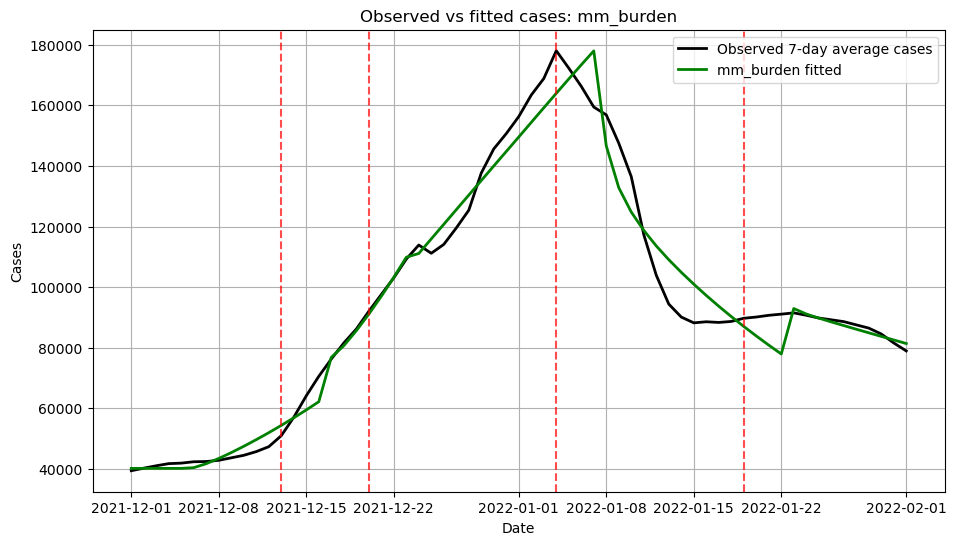

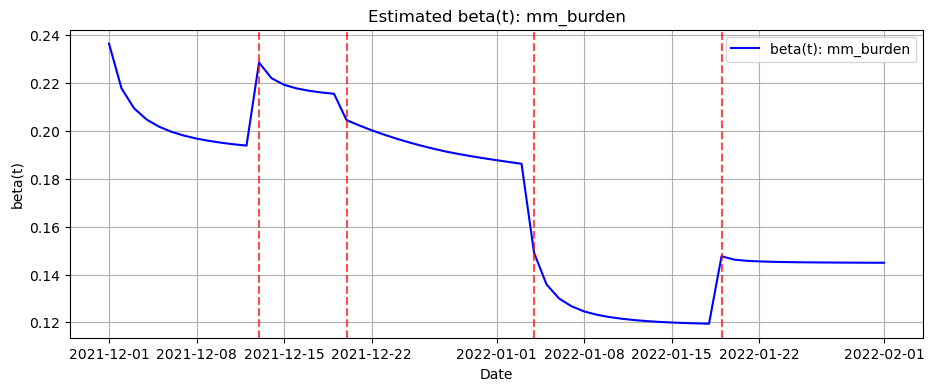

In [5]:
# =========================================================
# 10. fit final model
# =========================================================
x0, bounds = make_x0_bounds(MODEL_NAME, n_seg, obs_cases[0])

result = minimize(
    loss_fn,
    x0=x0,
    args=(MODEL_NAME,),
    method="L-BFGS-B",
    bounds=bounds,
)

print("Optimization success:", result.success)
print("Message:", result.message)

theta_hat = result.x

best = simulate_discrete_sir(
    model_name=MODEL_NAME,
    theta=theta_hat,
    burden=burden,
    gamma=gamma_fixed,
    N=N,
    T=T,
    tau=tau_fixed,
    segment_bounds=segment_bounds,
    n_seg=n_seg
)

mse = np.mean((best["fitted_cases"] - obs_cases) ** 2)
rmse = np.sqrt(mse)
log_mse = np.mean((np.log(best["fitted_cases"] + eps) - np.log(obs_cases + eps)) ** 2)

print("\nFinal model:", MODEL_NAME)
print("rho =", best["rho"])
print("I0 =", best["I0"])
print("gamma =", gamma_fixed)
print("MSE =", mse)
print("RMSE =", rmse)
print("log_MSE =", log_mse)

print("\nSegment parameters:")
for j, p in enumerate(best["params"], start=1):
    print(f"Segment {j}: {p}")

# optional save
np.save("../results/final_beta_path.npy", best["beta_path"])
np.save("../results/final_fitted_cases.npy", best["fitted_cases"])
np.save("../results/final_incidence.npy", best["incidence"])

# =========================================================
# 11. main fit plots
# =========================================================
plt.figure(figsize=(11, 6))
plt.plot(dates, obs_cases, label="Observed 7-day average cases", linewidth=2, color="black")
plt.plot(dates, best["fitted_cases"], label=f"{MODEL_NAME} fitted", linewidth=2, color="green")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
plt.title(f"Observed vs fitted cases: {MODEL_NAME}")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(11, 4))
plt.plot(dates, best["beta_path"], label=f"beta(t): {MODEL_NAME}", color="blue")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
plt.title(f"Estimated beta(t): {MODEL_NAME}")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.show()


Segment summary:
   segment  start_date    end_date  n_days  beta_start  beta_end  beta_mean  \
0        1  2021-12-01  2021-12-12      12    0.236503  0.193903   0.203704   
1        2  2021-12-13  2021-12-19       7    0.228638  0.215574   0.219484   
2        3  2021-12-20  2022-01-03      15    0.204588  0.186323   0.193682   
3        4  2022-01-04  2022-01-18      15    0.149151  0.119439   0.124920   
4        5  2022-01-19  2022-02-01      14    0.147642  0.144921   0.145413   

   beta_abs_change  beta_pct_change  observed_mean_cases  fitted_mean_cases  \
0        -0.042600       -18.012397         42785.380952       43431.851391   
1        -0.013064        -5.713902         69536.081633       68002.884974   
2        -0.018265        -8.927596        127234.695238      125862.909686   
3        -0.029713       -19.921097        125095.752381      127783.857432   
4        -0.002721        -1.842696         87905.071429       85585.987890   

   model_mean_incidence beta_dir

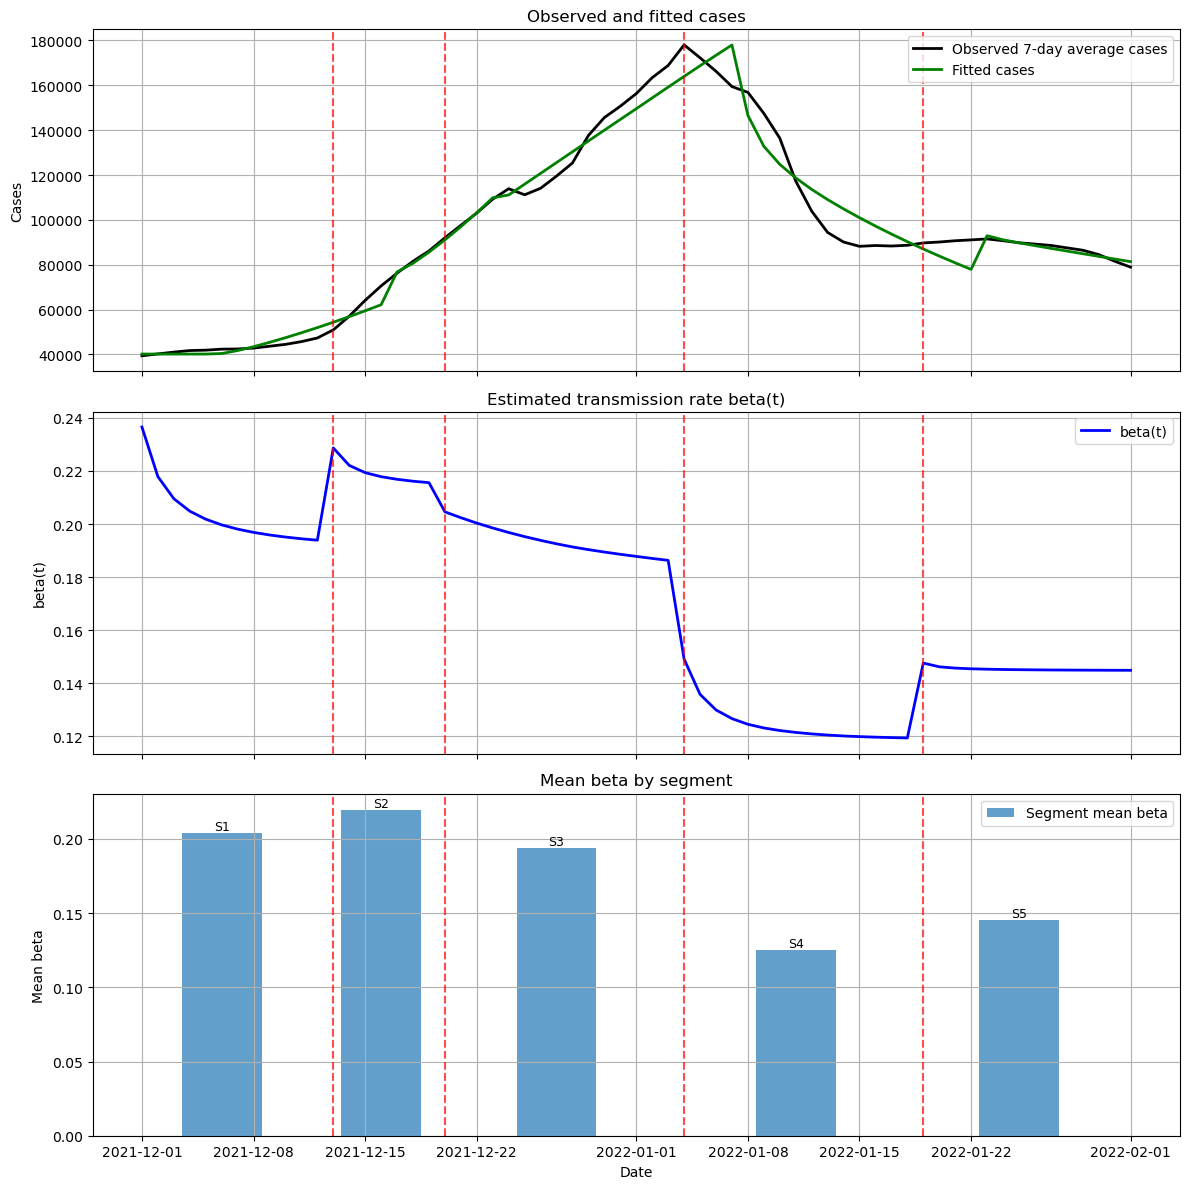


Compact interpretation draft:
Segment 1 (2021-12-01 to 2021-12-12): Pre-Plan B, beta moved from 0.2365 to 0.1939, average 0.2037, which is a decrease (-18.01% over the segment).
Segment 2 (2021-12-13 to 2021-12-19): Plan B introduced, beta moved from 0.2286 to 0.2156, average 0.2195, which is a decrease (-5.71% over the segment).
Segment 3 (2021-12-20 to 2022-01-03): Omicron-dominant growth, beta moved from 0.2046 to 0.1863, average 0.1937, which is a decrease (-8.93% over the segment).
Segment 4 (2022-01-04 to 2022-01-18): Post-holiday behaviour adjustment, beta moved from 0.1492 to 0.1194, average 0.1249, which is a decrease (-19.92% over the segment).
Segment 5 (2022-01-19 to 2022-02-01): Plan B relaxation, beta moved from 0.1476 to 0.1449, average 0.1454, which is a decrease (-1.84% over the segment).


In [6]:
# =========================================================
# 12. policy outcome analysis
# =========================================================
beta_path = np.array(best["beta_path"], dtype=float)
fitted_cases = np.array(best["fitted_cases"], dtype=float)
incidence = np.array(best["incidence"], dtype=float)

segment_summary = []

for j, (a, b) in enumerate(segment_bounds):
    beta_seg = beta_path[a:b]
    obs_seg = obs_cases[a:b]
    fit_seg = fitted_cases[a:b]
    inc_seg = incidence[a:b]

    beta_start = float(beta_seg[0])
    beta_end = float(beta_seg[-1])
    beta_mean = float(np.mean(beta_seg))
    beta_abs_change = beta_end - beta_start
    beta_pct_change = 100.0 * (beta_end - beta_start) / beta_start if beta_start != 0 else np.nan

    obs_mean = float(np.mean(obs_seg))
    fit_mean = float(np.mean(fit_seg))
    inc_mean = float(np.mean(inc_seg))

    segment_summary.append({
        "segment": j + 1,
        "start_date": dates.iloc[a].strftime("%Y-%m-%d"),
        "end_date": dates.iloc[b - 1].strftime("%Y-%m-%d"),
        "n_days": b - a,
        "beta_start": beta_start,
        "beta_end": beta_end,
        "beta_mean": beta_mean,
        "beta_abs_change": beta_abs_change,
        "beta_pct_change": beta_pct_change,
        "observed_mean_cases": obs_mean,
        "fitted_mean_cases": fit_mean,
        "model_mean_incidence": inc_mean
    })

seg_df = pd.DataFrame(segment_summary)

def classify_beta_change(x, tol=1e-4):
    if x > tol:
        return "increase"
    elif x < -tol:
        return "decrease"
    return "roughly flat"

seg_df["beta_direction"] = seg_df["beta_abs_change"].apply(classify_beta_change)

event_labels = {
    1: "Pre-Plan B",
    2: "Plan B introduced",
    3: "Omicron-dominant growth",
    4: "Post-holiday behaviour adjustment",
    5: "Plan B relaxation"
}
seg_df["event_label"] = seg_df["segment"].map(event_labels)

print("\nSegment summary:")
print(seg_df)

seg_df.to_csv("../results/segment_policy_summary.csv", index=False)

# =========================================================
# 13. summary plots
# =========================================================
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

# panel 1
axes[0].plot(dates, obs_cases, color="black", linewidth=2, label="Observed 7-day average cases")
axes[0].plot(dates, fitted_cases, color="green", linewidth=2, label="Fitted cases")
for d in break_dates:
    axes[0].axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
axes[0].set_title("Observed and fitted cases")
axes[0].set_ylabel("Cases")
axes[0].legend()
axes[0].grid()

# panel 2
axes[1].plot(dates, beta_path, color="blue", linewidth=2, label="beta(t)")
for d in break_dates:
    axes[1].axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
axes[1].set_title("Estimated transmission rate beta(t)")
axes[1].set_ylabel("beta(t)")
axes[1].legend()
axes[1].grid()

# panel 3
seg_mid_dates = []
for (a, b) in segment_bounds:
    mid_idx = (a + b - 1) // 2
    seg_mid_dates.append(dates.iloc[mid_idx])

axes[2].bar(seg_mid_dates, seg_df["beta_mean"], width=5, alpha=0.7, label="Segment mean beta")
for d in break_dates:
    axes[2].axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)

for i, row in seg_df.iterrows():
    axes[2].text(
        seg_mid_dates[i],
        row["beta_mean"],
        f"S{int(row['segment'])}",
        ha="center",
        va="bottom",
        fontsize=9
    )

axes[2].set_title("Mean beta by segment")
axes[2].set_ylabel("Mean beta")
axes[2].set_xlabel("Date")
axes[2].legend()
axes[2].grid()

plt.tight_layout()
plt.savefig("../results/policy_outcome_summary.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# 14. compact interpretation
# =========================================================
print("\nCompact interpretation draft:")
for _, row in seg_df.iterrows():
    print(
        f"Segment {int(row['segment'])} ({row['start_date']} to {row['end_date']}): "
        f"{row['event_label']}, beta moved from {row['beta_start']:.4f} "
        f"to {row['beta_end']:.4f}, average {row['beta_mean']:.4f}, "
        f"which is a {row['beta_direction']} "
        f"({row['beta_pct_change']:.2f}% over the segment)."
    )